# Grid và martingale (DCA) trên 47 coin perp, nến 5min

Notebook dùng `engine.py` (kernel numba) và `run_grid_martingale.py` cùng thư mục, dữ liệu `reference/data_5m/`. Sửa **ô Cấu hình** rồi chọn **Run All**.

- **Grid trung tính (A):**
  - Vùng giá quanh giá hiện tại, rộng ±2σ của một tháng, chia `N_LEVELS` bậc theo log.
  - Giá xuống mỗi bậc thì mua một phần, lên mỗi bậc thì bán một phần. Ở mép vùng, vị thế tối đa bằng 1× vốn.
  - `EXIT_MODE = 0` (A1): giá ra khỏi vùng thêm một bậc thì đóng hết bằng lệnh market, rồi dựng lại vùng mới. `EXIT_MODE = 1` (A2): giữ nguyên vị thế chờ giá quay lại.
- **Martingale DCA (B):**
  - Lệnh đầu là lệnh market. Có `N_SO` safety order, cái đầu cách giá vào `FIRST_DEV`; khoảng cách nhân `STEP_SCALE` sau mỗi bậc, khối lượng nhân `VOLUME_SCALE`.
  - Chốt lời `TAKE_PROFIT` trên giá vốn trung bình. `STOP_BEYOND > 0` thì cắt lỗ khi giá vượt qua safety order cuối thêm chừng đó.
  - Cả thang lệnh có tổng giá trị bằng 1× vốn.
- **Chi phí:** phí maker 0,02% cho lệnh limit; taker 0,05% + trượt giá 0,01% cho lệnh market; funding theo dữ liệu thực tế.
- **Danh mục:** mỗi coin một phần vốn bằng nhau. Lợi nhuận danh mục là trung bình lợi nhuận ngày của các phần vốn đang chạy.

Bản mặc định là thiết kế đã chốt trước khi chạy (INSIGHTS §9l). Mỗi lần đổi cấu hình rồi xem kết quả là **thêm một lần thử** trên cùng dữ liệu.

In [1]:
# CẤU HÌNH — sửa ô này trước khi chạy
KIND = "grid"            # "grid" hoặc "dca"
EXIT_MODE = 0            # grid: 0 = đóng và dựng lại khi ra khỏi vùng (A1), 1 = giữ vị thế (A2)
N_LEVELS = 20            # grid: số bậc
MIN_STEP_PCT = 0.4       # grid: khoảng cách tối thiểu giữa hai bậc (%)
DIRECTION = 1            # dca: 1 = long (mua khi giảm), -1 = short (bán khi tăng)
N_SO = 8                 # dca: số safety order
FIRST_DEV = 0.02         # dca: khoảng cách SO đầu
STEP_SCALE = 1.2
VOLUME_SCALE = 1.5
TAKE_PROFIT = 0.02
STOP_BEYOND = 0.0        # dca: 0 = không cắt lỗ; 0.10 = cắt khi vượt SO cuối 10%
PATH_MODE = 0            # 0 = nến tăng đi O→L→H→C; 1 = đảo ngược
TOUCH = False            # True = chạm là khớp (lạc quan)
ONE_SIDE = False         # True = không cho mua và bán cùng một nến
SYMBOLS = None           # None = cả 47 coin; hoặc danh sách, ví dụ ["avaxusdt", "dogeusdt"]
SAMPLE_COIN = "avaxusdt" # coin để vẽ chi tiết

In [2]:
import sys, math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

for parent in (Path.cwd(), *Path.cwd().parents):
    if (parent / "run_grid_martingale.py").is_file():
        sys.path.insert(0, str(parent)); break
    if (parent / "reference" / "grid_martingale" / "run_grid_martingale.py").is_file():
        sys.path.insert(0, str(parent / "reference" / "grid_martingale")); break
import run_grid_martingale as rg

strategy = rg.Strategy(KIND, exit_mode=EXIT_MODE, n_levels=N_LEVELS, min_step=math.log(1 + MIN_STEP_PCT / 100),
                       direction=DIRECTION, n_so=N_SO, first_dev=FIRST_DEV, step_scale=STEP_SCALE,
                       volume_scale=VOLUME_SCALE, take_profit=TAKE_PROFIT, stop_beyond=STOP_BEYOND,
                       path_mode=PATH_MODE, touch=TOUCH, one_side=ONE_SIDE)
symbols = SYMBOLS or sorted(p.name.split("_futures")[0] for p in rg.DATA_DIR.glob("*_futures_5min.csv"))
coins = {s: rg.load_coin(s) for s in symbols}
market = rg.market_returns(coins)
print(len(coins), "coin;", strategy)

47 coin; Strategy(kind='grid', exit_mode=0, n_levels=20, min_step=0.003992021269537457, direction=1, n_so=8, first_dev=0.02, step_scale=1.2, volume_scale=1.5, take_profit=0.02, stop_beyond=0.0, path_mode=0, touch=False, one_side=False)


In [3]:
res = rg.run_all(coins, {"chiến thuật": strategy})["chiến thuật"]
sleeves = rg.sleeve_stats(res["equities"])
table = pd.DataFrame({"chiến thuật": rg.evaluate("x", res["portfolio"], market, sleeves),
                      "long tất cả coin": rg.metrics(market, market)}).T
display(table.round(3))
port = res["portfolio"]
display(port.groupby(port.index.year).apply(lambda r: (1 + r).prod() - 1).rename("lợi nhuận năm").to_frame().round(3))
display(sleeves.sort_values("final").round(3))

,sharpe,sortino,cagr_at_20vol,max_dd_at_20vol,raw_ann_return,raw_ann_vol,calmar_at_20vol,alpha_ann,alpha_t_nw,beta,beta_t_nw,corr_market,total_return,max_dd,years_positive,years,sleeves_dd_gt_50,sleeves_ruined,median_sleeve_final
chiến thuật,-0.737,-0.639,-0.156,-0.649,-0.187,0.254,-0.240,-0.184,-1.507,-0.008,-2.460000e-01,-0.025,-0.723,-0.749,1.0,6.0,0.957,12.0,0.1
long tất cả coin,0.535,0.699,0.091,-0.287,0.430,0.804,0.316,0.000,2.948,1.000,3.969804e+16,1.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,lợi nhuận năm
2021,-0.445
2022,-0.073
2023,-0.004
2024,-0.085
2025,-0.404
2026,-0.010


,final,max_dd,ruined
axsusdt,0.0,-1.0,True
lunausdt,0.0,-1.0,True
maticusdt,0.0,-1.0,True
dogeusdt,0.0,-1.0,True
opusdt,0.0,-1.0,True
avaxusdt,0.0,-1.0,True
ftmusdt,0.0,-1.0,True
solusdt,0.0,-1.0,True
suiusdt,0.0,-1.0,True
tonusdt,0.0,-1.0,True


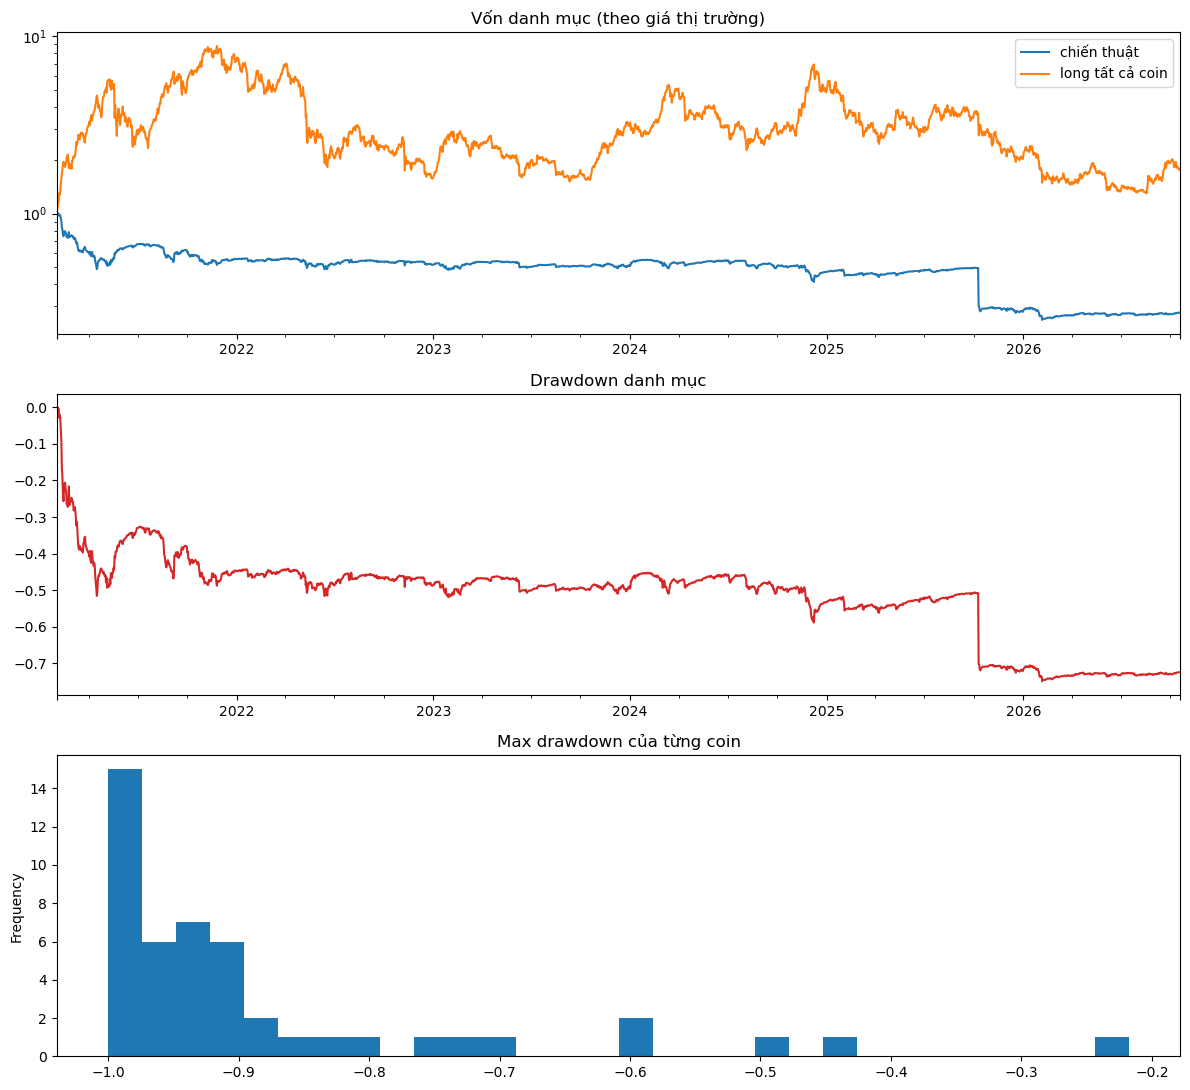

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(12, 11))
(1 + port).cumprod().plot(ax=axes[0], label="chiến thuật")
(1 + market.loc[port.index[0]:]).cumprod().plot(ax=axes[0], label="long tất cả coin")
axes[0].set_yscale("log"); axes[0].legend(); axes[0].set_title("Vốn danh mục (theo giá thị trường)")
equity = (1 + port).cumprod(); (equity / equity.cummax() - 1).plot(ax=axes[1], color="tab:red")
axes[1].set_title("Drawdown danh mục")
sleeves["max_dd"].astype(float).plot.hist(ax=axes[2], bins=30); axes[2].set_title("Max drawdown của từng coin")
plt.tight_layout(); plt.show()

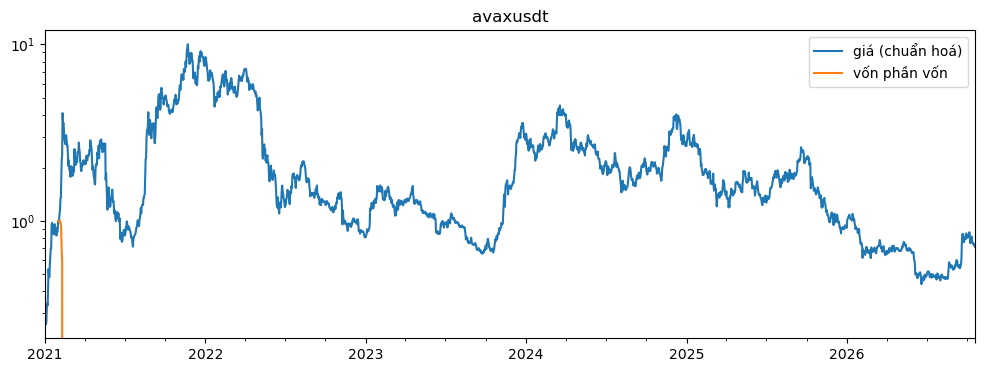

{'fills/cycles': 14.0, 'resets/take profits': 1.0, 'fees': 0.001, 'funding': 0.001, 'ruined': 1.0}


In [5]:
# Chi tiết một coin: giá và vốn của phần vốn đó
if SAMPLE_COIN in res["equities"]:
    coin = coins[SAMPLE_COIN]
    price = pd.Series(coin.c, index=pd.to_datetime(coin.ts)).resample("1D").last()
    fig, ax = plt.subplots(figsize=(12, 4))
    (price / price.dropna().iloc[30]).plot(ax=ax, label="giá (chuẩn hoá)")
    res["equities"][SAMPLE_COIN].plot(ax=ax, label="vốn phần vốn")
    ax.set_yscale("log"); ax.legend(); ax.set_title(SAMPLE_COIN); plt.show()
    print(dict(zip(["fills/cycles", "resets/take profits", "fees", "funding", "ruined", "", "", ""][: len(res["counters"].columns)],
                   res["counters"].loc[SAMPLE_COIN].round(3))))